In [1]:
!pip uninstall -y torch torchvision torchaudio torchtext


Found existing installation: torch 2.9.0+cu126
Uninstalling torch-2.9.0+cu126:
  Successfully uninstalled torch-2.9.0+cu126
Found existing installation: torchvision 0.24.0+cu126
Uninstalling torchvision-0.24.0+cu126:
  Successfully uninstalled torchvision-0.24.0+cu126
Found existing installation: torchaudio 2.9.0+cu126
Uninstalling torchaudio-2.9.0+cu126:
  Successfully uninstalled torchaudio-2.9.0+cu126


In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [3]:
!pip install torch==2.3.0 torchvision==0.18.0 torchaudio==2.3.0 --index-url https://download.pytorch.org/whl/cu121


Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.9/780.9 MB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 141.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 100.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 81.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 57.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 135.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 12.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 7.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/1

In [4]:
!pip install torchtext==0.18.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 79.9 MB/s eta 0:00:00


In [5]:
!python -m spacy download en_core_web_sm
!python -m spacy download fr_core_news_sm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 141.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 33.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [6]:
import torch
import torchtext

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("torchtext:", torchtext.__version__)


Torch: 2.3.0+cu121
CUDA available: True
torchtext: 0.18.0+cpu


In [19]:
# Cell 1: Import & Config

# %%
import os
import math
import time
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

import torchtext
torchtext.disable_torchtext_deprecation_warning()
from torchtext.data.utils import get_tokenizer  # mình không dùng nữa trong BPE, nhưng để đây cũng không sao

import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

nltk.download("punkt", quiet=True)

# ============ ĐƯỜNG DẪN DỮ LIỆU ============
# DATA_ROOT chứa: train.en, train.fr, val.en, val.fr, test.en, test.fr
DATA_ROOT = r"/content/drive/MyDrive/NLP PROJECT/data/multi30k_en_fr"

# ============ ĐƯỜNG DẪN LƯU MODEL ===========
MODEL_DIR = r"/content/drive/MyDrive/NLP PROJECT"
os.makedirs(MODEL_DIR, exist_ok=True)

# ============ ĐƯỜNG DẪN MODEL BPE ===========
SPM_SRC_MODEL = os.path.join(MODEL_DIR, "spm_en_bpe.model")
SPM_TRG_MODEL = os.path.join(MODEL_DIR, "spm_fr_bpe.model")

# ============ HYPERPARAMETER ===============
MAX_VOCAB_SIZE = 10_000

EMB_DIM = 512
HID_DIM = 512
NUM_LAYERS = 2
DROPOUT = 0.4

BATCH_SIZE = 64
NUM_EPOCHS = 25
LEARNING_RATE = 5e-4
TEACHER_FORCING_RATIO = 0.5
CLIP = 1.0

# ============ SCHEDULER ====================
SCHEDULER_FACTOR = 0.5
SCHEDULER_PATIENCE = 2
SCHEDULER_MIN_LR = 1e-6

EARLY_STOPPING_PATIENCE = 5

MAX_LEN_GENERATE = 50

# ============ THIẾT BỊ =====================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============ TOKEN ĐẶC BIỆT ===============
PAD_TOKEN = "<pad>"
SOS_TOKEN = "<sos>"
EOS_TOKEN = "<eos>"
UNK_TOKEN = "<unk>"

SPECIAL_TOKENS = [PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN]

print("DEVICE:", DEVICE)
print("MODEL_DIR:", MODEL_DIR)


DEVICE: cuda
MODEL_DIR: /content/drive/MyDrive/NLP PROJECT


In [20]:
# Cell 2: Data, BPE Tokenizer, Vocab, Dataset, DataLoader

from torchtext.vocab import build_vocab_from_iterator
import sentencepiece as spm

# ========== 1. Train hoặc load SentencePiece BPE ==========

def train_sentencepiece_if_needed():
    """
    Train SentencePiece BPE cho EN & FR nếu chưa có model .model.
    """
    if os.path.exists(SPM_SRC_MODEL) and os.path.exists(SPM_TRG_MODEL):
        print("✓ Đã tìm thấy SentencePiece models, không train lại.")
        return

    print("🚀 Đang train SentencePiece BPE cho EN...")
    spm.SentencePieceTrainer.train(
        input=os.path.join(DATA_ROOT, "train.en"),
        model_prefix=os.path.join(MODEL_DIR, "spm_en_bpe"),
        vocab_size=MAX_VOCAB_SIZE - len(SPECIAL_TOKENS),
        model_type="bpe",
        character_coverage=1.0,      # tiếng Anh/Pháp đủ dùng 1.0
        bos_id=-1,
        eos_id=-1,
        pad_id=-1,
        unk_id=0                     # vẫn cần unk cho SentencePiece
    )

    print("🚀 Đang train SentencePiece BPE cho FR...")
    spm.SentencePieceTrainer.train(
        input=os.path.join(DATA_ROOT, "train.fr"),
        model_prefix=os.path.join(MODEL_DIR, "spm_fr_bpe"),
        vocab_size=MAX_VOCAB_SIZE - len(SPECIAL_TOKENS),
        model_type="bpe",
        character_coverage=1.0,
        bos_id=-1,
        eos_id=-1,
        pad_id=-1,
        unk_id=0
    )

    print("✅ Train SentencePiece xong.")


train_sentencepiece_if_needed()

# Load lại model BPE
sp_src = spm.SentencePieceProcessor()
sp_src.load(SPM_SRC_MODEL)

sp_trg = spm.SentencePieceProcessor()
sp_trg.load(SPM_TRG_MODEL)

# ========== 2. Tokenizer BPE ==========

def src_bpe_tokenizer(text: str):
    # trả về list subword dạng string, vd ["▁I", "▁am", "▁a", "stu", "dent"]
    return sp_src.encode(text, out_type=str)

def trg_bpe_tokenizer(text: str):
    return sp_trg.encode(text, out_type=str)

# ========== 3. Đọc dữ liệu song ngữ (raw câu, chưa token) ==========

def read_parallel_file(root, split):
    """
    Đọc song song split.en và split.fr (raw text)
    Trả về list (en_sentence, fr_sentence)
    """
    en_path = os.path.join(root, f"{split}.en")
    fr_path = os.path.join(root, f"{split}.fr")

    assert os.path.exists(en_path), f"Không tìm thấy file: {en_path}"
    assert os.path.exists(fr_path), f"Không tìm thấy file: {fr_path}"

    pairs = []
    with open(en_path, "r", encoding="utf-8") as f_en, open(
        fr_path, "r", encoding="utf-8"
    ) as f_fr:
        for en_line, fr_line in zip(f_en, f_fr):
            en_line = en_line.strip()
            fr_line = fr_line.strip()
            if en_line == "" or fr_line == "":
                continue
            pairs.append((en_line, fr_line))
    return pairs

# ========== 4. Build vocab từ subword BPE ==========

def yield_tokens_en(pairs):
    for en, _ in pairs:
        yield src_bpe_tokenizer(en)

def yield_tokens_fr(pairs):
    for _, fr in pairs:
        yield trg_bpe_tokenizer(fr)

def build_vocab(pairs):
    """
    Xây vocab cho src (EN) và trg (FR) dựa trên subword BPE của tập train_pairs.
    """
    from collections import Counter

    def build_with_limit(yield_tokens_fn):
        counter = Counter()
        for tokens in yield_tokens_fn(pairs):
            counter.update(tokens)

        most_common = [w for w, _ in counter.most_common(MAX_VOCAB_SIZE)]

        # iterator phải yield list token-list
        def iterator():
            yield most_common

        vocab = build_vocab_from_iterator(
            iterator(),
            specials=SPECIAL_TOKENS,
            special_first=True,
        )

        vocab.set_default_index(vocab[UNK_TOKEN])
        return vocab

    src_vocab = build_with_limit(yield_tokens_en)
    trg_vocab = build_with_limit(yield_tokens_fr)
    return src_vocab, trg_vocab

# ========== 5. Dataset với BPE ==========

class TranslationDataset(Dataset):
    def __init__(self, pairs, src_vocab, trg_vocab):
        self.data = []
        self.src_vocab = src_vocab
        self.trg_vocab = trg_vocab

        for en, fr in pairs:
            src_tokens = [SOS_TOKEN] + src_bpe_tokenizer(en) + [EOS_TOKEN]
            trg_tokens = [SOS_TOKEN] + trg_bpe_tokenizer(fr) + [EOS_TOKEN]

            src_ids = torch.tensor(
                [src_vocab[token] for token in src_tokens],
                dtype=torch.long,
            )
            trg_ids = torch.tensor(
                [trg_vocab[token] for token in trg_tokens],
                dtype=torch.long,
            )

            self.data.append((src_ids, trg_ids))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

# ========== 6. collate_fn & DataLoader ==========

def collate_fn(batch, pad_idx):
    """
    batch: list[(src_ids, trg_ids)]
    Trả về:
        src_padded:  [B, src_len]
        src_lengths: [B]
        trg_padded:  [B, trg_len]
        trg_lengths: [B]
    """
    src_list, trg_list = zip(*batch)

    src_lengths = torch.tensor([len(s) for s in src_list], dtype=torch.long)
    trg_lengths = torch.tensor([len(t) for t in trg_list], dtype=torch.long)

    # sort theo src_len giảm dần
    src_lengths, sort_idx = src_lengths.sort(descending=True)
    src_list = [src_list[i] for i in sort_idx]
    trg_list = [trg_list[i] for i in sort_idx]
    trg_lengths = torch.tensor([len(t) for t in trg_list], dtype=torch.long)

    src_padded = pad_sequence(src_list, batch_first=True, padding_value=pad_idx)
    trg_padded = pad_sequence(trg_list, batch_first=True, padding_value=pad_idx)

    return (
        src_padded.to(DEVICE),
        src_lengths.to(DEVICE),
        trg_padded.to(DEVICE),
        trg_lengths.to(DEVICE),
    )

def build_dataloaders():
    train_pairs = read_parallel_file(DATA_ROOT, "train")
    val_pairs   = read_parallel_file(DATA_ROOT, "val")
    test_pairs  = read_parallel_file(DATA_ROOT, "test")

    src_vocab, trg_vocab = build_vocab(train_pairs)

    pad_idx = src_vocab[PAD_TOKEN]

    train_dataset = TranslationDataset(train_pairs, src_vocab, trg_vocab)
    val_dataset   = TranslationDataset(val_pairs, src_vocab, trg_vocab)
    test_dataset  = TranslationDataset(test_pairs, src_vocab, trg_vocab)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=lambda b: collate_fn(b, pad_idx),
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=lambda b: collate_fn(b, pad_idx),
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=1,
        shuffle=False,
        collate_fn=lambda b: collate_fn(b, pad_idx),
    )

    return train_loader, val_loader, test_loader, src_vocab, trg_vocab, pad_idx


✓ Đã tìm thấy SentencePiece models, không train lại.


In [21]:

# Cell 3: Model với BiLSTM Encoder + Luong Attention (Luong-style)

# %%
import random

class Encoder(nn.Module):
    """
    BiLSTM Encoder
    - Mỗi hướng có hidden size = hid_dim // 2
    - Kết quả concat lại => output dim = hid_dim (tương thích decoder)
    """
    def __init__(self, input_dim, emb_dim, hid_dim, num_layers, dropout):
        super().__init__()
        self.hid_dim = hid_dim
        self.num_layers = num_layers

        self.embedding = nn.Embedding(input_dim, emb_dim)
        self.dropout = nn.Dropout(dropout)

        # BiLSTM: mỗi hướng = hid_dim // 2 -> concat 2 hướng = hid_dim
        assert hid_dim % 2 == 0, "HID_DIM phải chẵn để chia 2 cho BiLSTM."
        self.rnn = nn.LSTM(
            emb_dim,
            hid_dim // 2,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True,
            bidirectional=True,
        )

    def _cat_directions(self, h):
        """
        h: [num_layers * 2, B, hid_dim // 2]
        Trả về: [num_layers, B, hid_dim] bằng cách concat forward + backward
        """
        num_layers_times_directions, batch_size, hid_half = h.size()
        assert num_layers_times_directions == self.num_layers * 2

        # [num_layers, 2, B, hid_half]
        h = h.view(self.num_layers, 2, batch_size, hid_half)
        # concat 2 hướng ở dim hidden: [num_layers, B, hid_dim]
        h = torch.cat((h[:, 0, :, :], h[:, 1, :, :]), dim=2)
        return h

    def forward(self, src, src_lengths):
        # src: [B, src_len]
        embedded = self.dropout(self.embedding(src))  # [B, src_len, emb_dim]

        packed = pack_padded_sequence(
            embedded, src_lengths.cpu(), batch_first=True, enforce_sorted=True
        )
        packed_outputs, (hidden, cell) = self.rnn(packed)
        outputs, _ = pad_packed_sequence(packed_outputs, batch_first=True)
        # outputs: [B, src_len, hid_dim] (2 * (hid_dim//2))

        # hidden, cell: [num_layers*2, B, hid_dim//2] -> [num_layers, B, hid_dim]
        hidden = self._cat_directions(hidden)
        cell = self._cat_directions(cell)

        return outputs, hidden, cell


class AttnDecoder(nn.Module):
    """
    Luong attention (dot) + LSTM Decoder (1 hướng, left-to-right)
    - encoder_outputs: [B, src_len, hid_dim]
    - decoder output:  [B, 1, hid_dim]
    """
    def __init__(self, output_dim, emb_dim, hid_dim, num_layers, dropout):
        super().__init__()
        self.output_dim = output_dim
        self.hid_dim = hid_dim
        self.num_layers = num_layers

        self.embedding = nn.Embedding(output_dim, emb_dim)
        self.dropout = nn.Dropout(dropout)

        self.rnn = nn.LSTM(
            emb_dim,
            hid_dim,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True,
        )
        # concat [decoder_output; context] -> Linear
        self.fc_out = nn.Linear(hid_dim * 2, output_dim)

    def forward(self, input, hidden, cell, encoder_outputs):
        """
        input: [B]
        hidden, cell: [num_layers, B, hid_dim]
        encoder_outputs: [B, src_len, hid_dim]
        """
        input = input.unsqueeze(1)  # [B, 1]
        embedded = self.dropout(self.embedding(input))  # [B, 1, emb_dim]

        output, (hidden, cell) = self.rnn(embedded, (hidden, cell))
        # output: [B, 1, hid_dim]

        # Luong dot attention: scores = output @ encoder_outputs^T
        # encoder_outputs: [B, src_len, hid_dim] -> [B, hid_dim, src_len]
        scores = torch.bmm(output, encoder_outputs.transpose(1, 2))  # [B, 1, src_len]
        attn_weights = F.softmax(scores, dim=-1)                     # [B, 1, src_len]

        # context: weighted sum of encoder_outputs
        context = torch.bmm(attn_weights, encoder_outputs)           # [B, 1, hid_dim]

        # concat context + decoder output
        concat = torch.cat((output, context), dim=2)                 # [B, 1, 2*hid_dim]
        prediction = self.fc_out(concat.squeeze(1))                  # [B, output_dim]

        return prediction, hidden, cell, attn_weights.squeeze(1)


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder, device=DEVICE):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

        assert encoder.hid_dim == decoder.hid_dim, \
            "Encoder HID_DIM và Decoder HID_DIM phải bằng nhau!"

    def forward(self, src, src_lengths, trg, teacher_forcing_ratio=0.5):
        """
        src: [B, src_len]
        trg: [B, trg_len]
        """
        batch_size = src.size(0)
        trg_len = trg.size(1)
        trg_vocab_size = self.decoder.output_dim

        outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)

        encoder_outputs, hidden, cell = self.encoder(src, src_lengths)

        input = trg[:, 0]  # <sos>

        for t in range(1, trg_len):
            output, hidden, cell, _ = self.decoder(
                input, hidden, cell, encoder_outputs
            )
            outputs[:, t, :] = output

            top1 = output.argmax(1)

            if random.random() < teacher_forcing_ratio:
                input = trg[:, t]
            else:
                input = top1

        return outputs


In [22]:

# Cell 4: Train / Eval / Translate / BLEU

# %%
def epoch_time(start_time, end_time):
    elapsed = end_time - start_time
    mins = int(elapsed / 60)
    secs = int(elapsed - mins * 60)
    return mins, secs
def bpe_decode(tokens):
    """
    tokens: list các subword, ví dụ ['▁Un', '▁homme', '▁fait', '▁du', '▁vélo']
    trả về: 'Un homme fait du vélo'
    """
    s = "".join(tokens)          # '▁Un▁homme▁fait▁du▁vélo'
    s = s.replace("▁", " ").strip()
    return s


def train_one_epoch(model, iterator, optimizer, criterion, pad_idx):
    model.train()
    epoch_loss = 0

    for src, src_len, trg, trg_len in tqdm(iterator, desc="Đang train", total=len(iterator)):
        optimizer.zero_grad()

        output = model(
            src,
            src_len,
            trg,
            teacher_forcing_ratio=TEACHER_FORCING_RATIO,
        )

        # output: [B, trg_len, output_dim]
        output_dim = output.shape[-1]
        output = output[:, 1:, :].contiguous().view(-1, output_dim)
        trg = trg[:, 1:].contiguous().view(-1)

        loss = criterion(output, trg)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
        optimizer.step()

        epoch_loss += loss.item()

    return epoch_loss / len(iterator)


def evaluate(model, iterator, criterion, pad_idx):
    model.eval()
    epoch_loss = 0

    with torch.no_grad():
        for src, src_len, trg, trg_len in tqdm(iterator, desc="Đang evaluate", total=len(iterator)):
            output = model(src, src_len, trg, teacher_forcing_ratio=0.0)

            output_dim = output.shape[-1]
            output = output[:, 1:, :].contiguous().view(-1, output_dim)
            trg = trg[:, 1:].contiguous().view(-1)

            loss = criterion(output, trg)
            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

###############################################
# BEAM SEARCH DECODING CHO SEQ2SEQ + ATTENTION
###############################################
def beam_search_decode(model, encoder_outputs, hidden, cell, trg_vocab, beam_size=5, max_len=50):
    """
    Beam search decoding cho Seq2Seq + Attention.
    Trả về: danh sách token ID của câu được dịch.
    """

    EOS = trg_vocab[EOS_TOKEN]

    # mỗi phần tử beam = (score, seq, hidden, cell)
    beams = [(0.0, [trg_vocab[SOS_TOKEN]], hidden, cell)]  # score = log prob

    finished = []

    for _ in range(max_len):
        new_beams = []

        for score, seq, h, c in beams:
            last_token = seq[-1]

            if last_token == EOS:
                # finished chỉ lưu (score, seq)
                finished.append((score, seq))
                continue

            input_token = torch.tensor([last_token], dtype=torch.long, device=DEVICE)

            with torch.no_grad():
                output, new_h, new_c, _ = model.decoder(
                    input_token, h, c, encoder_outputs
                )

            # log-softmax để cộng log-prob
            log_probs = torch.log_softmax(output, dim=1)  # [1, vocab]

            topk_log_probs, topk_ids = torch.topk(log_probs, beam_size, dim=1)

            for k in range(beam_size):
                candidate_score = score + topk_log_probs[0][k].item()
                candidate_seq = seq + [topk_ids[0][k].item()]
                new_beams.append((candidate_score, candidate_seq, new_h, new_c))

        # giữ lại beam tốt nhất
        new_beams = sorted(new_beams, key=lambda x: x[0], reverse=True)[:beam_size]
        beams = new_beams

        if len(finished) >= beam_size:
            break

    if len(finished) == 0:
        finished = beams  # ở đây mỗi phần tử là (score, seq, h, c)

    # chọn câu có điểm cao nhất
    best = sorted(finished, key=lambda x: x[0], reverse=True)[0]
    best_score = best[0]
    best_seq = best[1]
    return best_seq

def translate_sentence(
    sentence: str,
    model,
    src_vocab,
    trg_vocab,
    beam_size=5,
    max_len=50
):
    """
    Dịch 1 câu EN (raw text) bằng beam search + BPE.
    """
    model.eval()

    # 1. BPE tokenize câu tiếng Anh
    bpe_tokens = src_bpe_tokenizer(sentence)   # dùng SentencePiece
    tokens_en = [SOS_TOKEN] + bpe_tokens + [EOS_TOKEN]

    # 2. Map sang ID
    src_ids = [src_vocab[token] for token in tokens_en]

    src_tensor = torch.tensor(src_ids).unsqueeze(0).to(DEVICE)
    src_len = torch.tensor([len(src_ids)]).to(DEVICE)

    # 3. Encoder
    with torch.no_grad():
        encoder_outputs, hidden, cell = model.encoder(src_tensor, src_len)

    # 4. Beam search
    best_seq = beam_search_decode(
        model, encoder_outputs, hidden, cell, trg_vocab,
        beam_size=beam_size,
        max_len=max_len
    )

    # 5. ID -> token
    trg_tokens = [trg_vocab.lookup_token(idx) for idx in best_seq]

    # bỏ <sos>, cắt tại <eos>
    trg_tokens = trg_tokens[1:]
    if EOS_TOKEN in trg_tokens:
        trg_tokens = trg_tokens[:trg_tokens.index(EOS_TOKEN)]

    # 🔧 decode BPE -> câu bình thường
    return bpe_decode(trg_tokens)


def translate_from_ids(src_ids, model, trg_vocab, beam_size=5, max_len=50):
    """
    Dịch từ dãy ID src (đã là BPE + SOS/EOS/PAD) -> list token trg (BPE).
    src_ids: list[int]
    """
    model.eval()

    # Chuyển về tensor, dùng đúng độ dài thực (không cần PAD vì src_ids đã cắt rồi)
    src_tensor = torch.tensor(src_ids, dtype=torch.long).unsqueeze(0).to(DEVICE)
    src_len = torch.tensor([len(src_ids)], dtype=torch.long).to(DEVICE)

    with torch.no_grad():
        encoder_outputs, hidden, cell = model.encoder(src_tensor, src_len)

    best_seq = beam_search_decode(
        model, encoder_outputs, hidden, cell, trg_vocab,
        beam_size=beam_size,
        max_len=max_len
    )

    trg_tokens = [trg_vocab.lookup_token(idx) for idx in best_seq]

    # Bỏ <sos>, cắt tại <eos>
    trg_tokens = trg_tokens[1:]
    if EOS_TOKEN in trg_tokens:
        trg_tokens = trg_tokens[:trg_tokens.index(EOS_TOKEN)]

    return trg_tokens  # trả về list token (BPE)


def compute_bleu(model, test_loader, src_vocab, trg_vocab, max_samples=None):
    smoothie = SmoothingFunction().method4
    model.eval()
    scores = []

    with torch.no_grad():
        for src, src_len, trg, trg_len in tqdm(test_loader, desc="BLEU"):

            batch_size = src.size(0)

            for b in range(batch_size):

                # Nếu chỉ tính max_samples → dừng sớm.
                if max_samples is not None and len(scores) >= max_samples:
                    return sum(scores) / len(scores)

                # ===== Reference =====
                trg_ids = trg[b].tolist()
                trg_tokens = [trg_vocab.lookup_token(idx) for idx in trg_ids]
                clean_trg = [
                    tok for tok in trg_tokens
                    if tok not in [SOS_TOKEN, EOS_TOKEN, PAD_TOKEN]
                ]
                reference = [clean_trg]

                # ===== Source: lấy đúng length thật, không dùng PAD =====
                # src_len[b] là độ dài thật (không tính pad) do collate_fn trả về
                true_len = src_len[b].item()
                src_ids = src[b, :true_len].tolist()    # cắt PAD

                # ===== Hypothesis =====
                hypothesis_tokens = translate_from_ids(
                    src_ids, model, trg_vocab
                )

                bleu = sentence_bleu(
                    reference,
                    hypothesis_tokens,
                    smoothing_function=smoothie
                )
                scores.append(bleu)

    return sum(scores) / len(scores) if scores else 0.0




In [ ]:

# Cell 5: Train + Lưu model + Vẽ loss + Tính BLEU

# %%

def train_and_eval(resume=True):
    print("Thiết bị:", DEVICE)

    # 1) Dataloader
    (
        train_loader,
        val_loader,
        test_loader,
        src_vocab,
        trg_vocab,
        pad_idx,
    ) = build_dataloaders()

    input_dim = len(src_vocab)
    output_dim = len(trg_vocab)

    print(f"Vocab EN size: {input_dim}, Vocab FR size: {output_dim}")

    # 2) Model
    encoder = Encoder(
        input_dim=input_dim,
        emb_dim=EMB_DIM,
        hid_dim=HID_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
    )
    decoder = AttnDecoder(
        output_dim=output_dim,
        emb_dim=EMB_DIM,
        hid_dim=HID_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
    )

    model = Seq2Seq(encoder, decoder, device=DEVICE).to(DEVICE)
    print(model)

    # 3) Loss + Optimizer + Scheduler
    criterion = nn.CrossEntropyLoss(ignore_index=pad_idx)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=SCHEDULER_FACTOR,
        patience=SCHEDULER_PATIENCE,
        min_lr=SCHEDULER_MIN_LR,
        verbose=True,
    )

    # Path
    best_model_path = os.path.join(MODEL_DIR, "best_model_subword.pth")
    training_state_path = os.path.join(MODEL_DIR, "last_checkpoint_subword.pth")

    # 4) Resume
    start_epoch = 0
    best_valid_loss = float("inf")
    epochs_no_improve = 0
    train_losses = []
    val_losses = []

    if resume and os.path.exists(training_state_path):
        print("🔁 Đang load checkpoint để train tiếp...")
        ckpt = torch.load(training_state_path, map_location=DEVICE)

        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])

        if "scheduler_state_dict" in ckpt:
            scheduler.load_state_dict(ckpt["scheduler_state_dict"])

        start_epoch       = ckpt["epoch"] + 1
        best_valid_loss   = ckpt["best_valid_loss"]
        epochs_no_improve = ckpt["epochs_no_improve"]
        train_losses      = ckpt["train_losses"]
        val_losses        = ckpt["val_losses"]

        src_vocab = ckpt["src_vocab"]
        trg_vocab = ckpt["trg_vocab"]
        pad_idx   = ckpt["pad_idx"]

        print(f"✅ Resume từ epoch {start_epoch}/{NUM_EPOCHS-1}")
    else:
        print("🚀 Bắt đầu train mới từ epoch 0.")

    # 5) Training Loop
    if start_epoch < NUM_EPOCHS:
        for epoch in range(start_epoch, NUM_EPOCHS):

            start_time = time.time()
            print(f"\n===== Epoch {epoch + 1}/{NUM_EPOCHS} =====")

            train_loss = train_one_epoch(model, train_loader, optimizer, criterion, pad_idx)
            val_loss   = evaluate(model, val_loader, criterion, pad_idx)

            train_losses.append(train_loss)
            val_losses.append(val_loss)

            # Update scheduler
            scheduler.step(val_loss)

            # In LR hiện tại
            lr = optimizer.param_groups[0]["lr"]
            print(f"\tCurrent LR = {lr:.6f}")

            # Logging
            mins, secs = epoch_time(start_time, time.time())
            print(f"Epoch {epoch+1:02} | Time: {mins}m {secs}s")
            print(f"\tTrain Loss: {train_loss:.3f} | PPL: {math.exp(train_loss):.3f}")
            print(f"\tVal   Loss: {val_loss:.3f} | PPL: {math.exp(val_loss):.3f}")

            # 5.1 Save best model
            if val_loss < best_valid_loss:
                best_valid_loss = val_loss
                epochs_no_improve = 0

                torch.save(
                    {
                        "model_state_dict": model.state_dict(),
                        "src_vocab": src_vocab,
                        "trg_vocab": trg_vocab,
                        "pad_idx": pad_idx,
                    },
                    best_model_path
                )
                print(f"💾 Lưu best model tại: {best_model_path}")
            else:
                epochs_no_improve += 1

            # 5.2 Save training state
            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "best_valid_loss": best_valid_loss,
                    "epochs_no_improve": epochs_no_improve,
                    "train_losses": train_losses,
                    "val_losses": val_losses,
                    "src_vocab": src_vocab,
                    "trg_vocab": trg_vocab,
                    "pad_idx": pad_idx,
                },
                training_state_path
            )
            print(f"💾 Lưu checkpoint tại: {training_state_path}")

            if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
                print("⛔ Early stopping do val_loss không giảm.")
                break

    # 6) Vẽ Loss Curve
    if len(train_losses) > 0:
        plt.figure()
        plt.plot(train_losses, label="Train Loss")
        plt.plot(val_losses, label="Val Loss")
        plt.legend()
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Loss Curve")
        plt.savefig(os.path.join(MODEL_DIR, "loss_curve_subword.png"))
        plt.close()
        print("📈 Đã lưu loss curve.")

    # 7) Load best model → BLEU full test
    print("Đang tính BLEU trên toàn bộ test set...")
    ckpt_best = torch.load(best_model_path, map_location=DEVICE)
    model.load_state_dict(ckpt_best["model_state_dict"])
    src_vocab = ckpt_best["src_vocab"]
    trg_vocab = ckpt_best["trg_vocab"]
    pad_idx   = ckpt_best["pad_idx"]

    bleu = compute_bleu(model, test_loader, src_vocab, trg_vocab, max_samples=None)
    print(f"🌟 BLEU FULL TEST = {bleu:.4f}")

    return model, src_vocab, trg_vocab
model, src_vocab, trg_vocab = train_and_eval()


Thiết bị: cuda
Vocab EN size: 8835, Vocab FR size: 8950
Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(8835, 512)
    (dropout): Dropout(p=0.4, inplace=False)
    (rnn): LSTM(512, 256, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  )
  (decoder): AttnDecoder(
    (embedding): Embedding(8950, 512)
    (dropout): Dropout(p=0.4, inplace=False)
    (rnn): LSTM(512, 512, num_layers=2, batch_first=True, dropout=0.4)
    (fc_out): Linear(in_features=1024, out_features=8950, bias=True)
  )
)
🔁 Đang load checkpoint để train tiếp...
✅ Resume từ epoch 17/24

===== Epoch 18/25 =====


Đang train:   0%|          | 0/454 [00:00<?, ?it/s]

Đang evaluate:   0%|          | 0/16 [00:00<?, ?it/s]

	Current LR = 0.000125
Epoch 18 | Time: 1m 42s
	Train Loss: 1.065 | PPL: 2.901
	Val   Loss: 3.620 | PPL: 37.333
💾 Lưu checkpoint tại: /content/drive/MyDrive/NLP PROJECT/last_checkpoint_subword.pth
⛔ Early stopping do val_loss không giảm.
📈 Đã lưu loss curve.
Đang tính BLEU trên toàn bộ test set...


BLEU:   0%|          | 0/1000 [00:00<?, ?it/s]

🌟 BLEU FULL TEST = 0.4887


In [ ]:
def load_best_model_for_test():
    print("Thiết bị:", DEVICE)

    (
        train_loader,
        val_loader,
        test_loader,
        src_vocab,
        trg_vocab,
        pad_idx,
    ) = build_dataloaders()

    input_dim = len(src_vocab)
    output_dim = len(trg_vocab)

    encoder = Encoder(
        input_dim=input_dim,
        emb_dim=EMB_DIM,
        hid_dim=HID_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
    )
    decoder = AttnDecoder(
        output_dim=output_dim,
        emb_dim=EMB_DIM,
        hid_dim=HID_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
    )

    model = Seq2Seq(encoder, decoder, device=DEVICE).to(DEVICE)

    best_model_path = os.path.join(MODEL_DIR, "best_model_subword.pth")
    ckpt_best = torch.load(best_model_path, map_location=DEVICE)

    model.load_state_dict(ckpt_best["model_state_dict"])
    src_vocab = ckpt_best["src_vocab"]
    trg_vocab = ckpt_best["trg_vocab"]
    pad_idx   = ckpt_best["pad_idx"]

    print("Đang tính BLEU trên toàn bộ test set...")
    model.eval()
    bleu = compute_bleu(model, test_loader, src_vocab, trg_vocab, max_samples=None)
    print(f"🌟 BLEU FULL TEST = {bleu:.4f}  ({bleu*100:.2f}%)")

    return model, src_vocab, trg_vocab, test_loader


In [ ]:
# Cell 6: Gọi train_and_eval() và test dịch

# %%
model, src_vocab, trg_vocab, test_loader = load_best_model_for_test()

# ===== Test 5 câu dịch =====
test_sentences = [
    "a man is riding a bicycle in the street",
    "a dog is running across the field",
    "two children are playing with a ball in the park",
    "a group of people are sitting around a table",
    "a woman is cooking food in the kitchen"
]

for i, sent in enumerate(test_sentences, start=1):
    print(f"\n===== Example {i} =====")
    print("EN:", sent)
    print("FR:", translate_sentence(
        sent,
        model,
        src_vocab,
        trg_vocab,
        beam_size=5   # bạn giữ nguyên beam size
    ))


Thiết bị: cuda
Đang tính BLEU trên toàn bộ test set...


BLEU:   0%|          | 0/1000 [00:00<?, ?it/s]

🌟 BLEU FULL TEST = 0.4887  (48.87%)

===== Example 1 =====
EN: a man is riding a bicycle in the street
FR: Un homme fait du vélo dans la rue

===== Example 2 =====
EN: a dog is running across the field
FR: Un chien court sur le terrain

===== Example 3 =====
EN: two children are playing with a ball in the park
FR: deux enfants jouent avec un ballon dans le parc

===== Example 4 =====
EN: a group of people are sitting around a table
FR: Un groupe de personnes sont assis autour d'une table

===== Example 5 =====
EN: a woman is cooking food in the kitchen
FR: Une femme cuisine de la nourriture dans la cuisine


In [ ]:
# Cell 6: Lấy câu từ test_loader, dịch + in BLEU từng câu

from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
smoothie = SmoothingFunction().method4

def bpe_decode(tokens):
    s = "".join(tokens)
    s = s.replace("▁", " ").strip()
    return s

def decode_ids_to_sentence(ids, vocab):
    """
    ids: list[int]
    vocab: src_vocab hoặc trg_vocab
    """
    tokens = [vocab.lookup_token(i) for i in ids]
    tokens = [t for t in tokens if t not in [SOS_TOKEN, EOS_TOKEN, PAD_TOKEN]]
    return bpe_decode(tokens)


# 1) Load model + dataloader như cũ
model, src_vocab, trg_vocab, test_loader = load_best_model_for_test()

# 2) Số câu muốn xem chi tiết
NUM_EXAMPLES = 10
count = 0

print("\n=== VÍ DỤ TỪ TEST_LOADER (có BLEU từng câu) ===")

for src, src_len, trg, trg_len in test_loader:
    batch_size = src.size(0)

    for b in range(batch_size):
        if count >= NUM_EXAMPLES:
            break

        # ---- Lấy source thật (EN) ----
        true_len = src_len[b].item()
        src_ids = src[b, :true_len].tolist()
        en_sent = decode_ids_to_sentence(src_ids, src_vocab)

        # ---- Lấy reference target (FR REF) ----
        trg_ids = trg[b].tolist()
        fr_ref = decode_ids_to_sentence(trg_ids, trg_vocab)

        # ---- Dịch lại bằng model (FR HYP) ----
        # translate_from_ids trả về list token BPE
        hyp_bpe_tokens = translate_from_ids(src_ids, model, trg_vocab)
        fr_hyp = bpe_decode(hyp_bpe_tokens)

        # ---- Tính BLEU cho câu này ----
        ref_tokens = fr_ref.split()
        hyp_tokens = fr_hyp.split()

        bleu = sentence_bleu([ref_tokens], hyp_tokens, smoothing_function=smoothie)

        print(f"\n===== Example {count+1} =====")
        print("EN     :", en_sent)
        print("FR REF :", fr_ref)
        print("FR HYP :", fr_hyp)
        print(f"BLEU câu này: {bleu*100:.2f}%")

        count += 1

    if count >= NUM_EXAMPLES:
        break


Thiết bị: cuda
Đang tính BLEU trên toàn bộ test set...


BLEU:   0%|          | 0/1000 [00:00<?, ?it/s]

🌟 BLEU FULL TEST = 0.4887  (48.87%)

=== VÍ DỤ TỪ TEST_LOADER (có BLEU từng câu) ===

===== Example 1 =====
EN     : A man in an orange hat starring at something.
FR REF : Un homme avec un chapeau orange regardant quelque chose.
FR HYP : Un homme avec un chapeau orange regarde quelque chose.
BLEU câu này: 66.06%

===== Example 2 =====
EN     : A Boston Terrier is running on lush green grass in front of a white fence.
FR REF : Un terrier de Boston court sur l'herbe verdoyante devant une clôture blanche.
FR HYP : Un agent de motocross court sur une pelouse verte devant une clôture blanche.
BLEU câu này: 24.71%

===== Example 3 =====
EN     : A girl in karate uniform breaking a stick with a front kick.
FR REF : Une fille en tenue de karaté brisant un bâton avec un coup de pied.
FR HYP : Une fille en tenue de karaté avec un bâton avec un combat.
BLEU câu này: 53.67%

===== Example 4 =====
EN     : Five people wearing winter jackets and helmets stand in the snow, with snowmobiles in the bac

# LOAD LAST MODEL so sánh


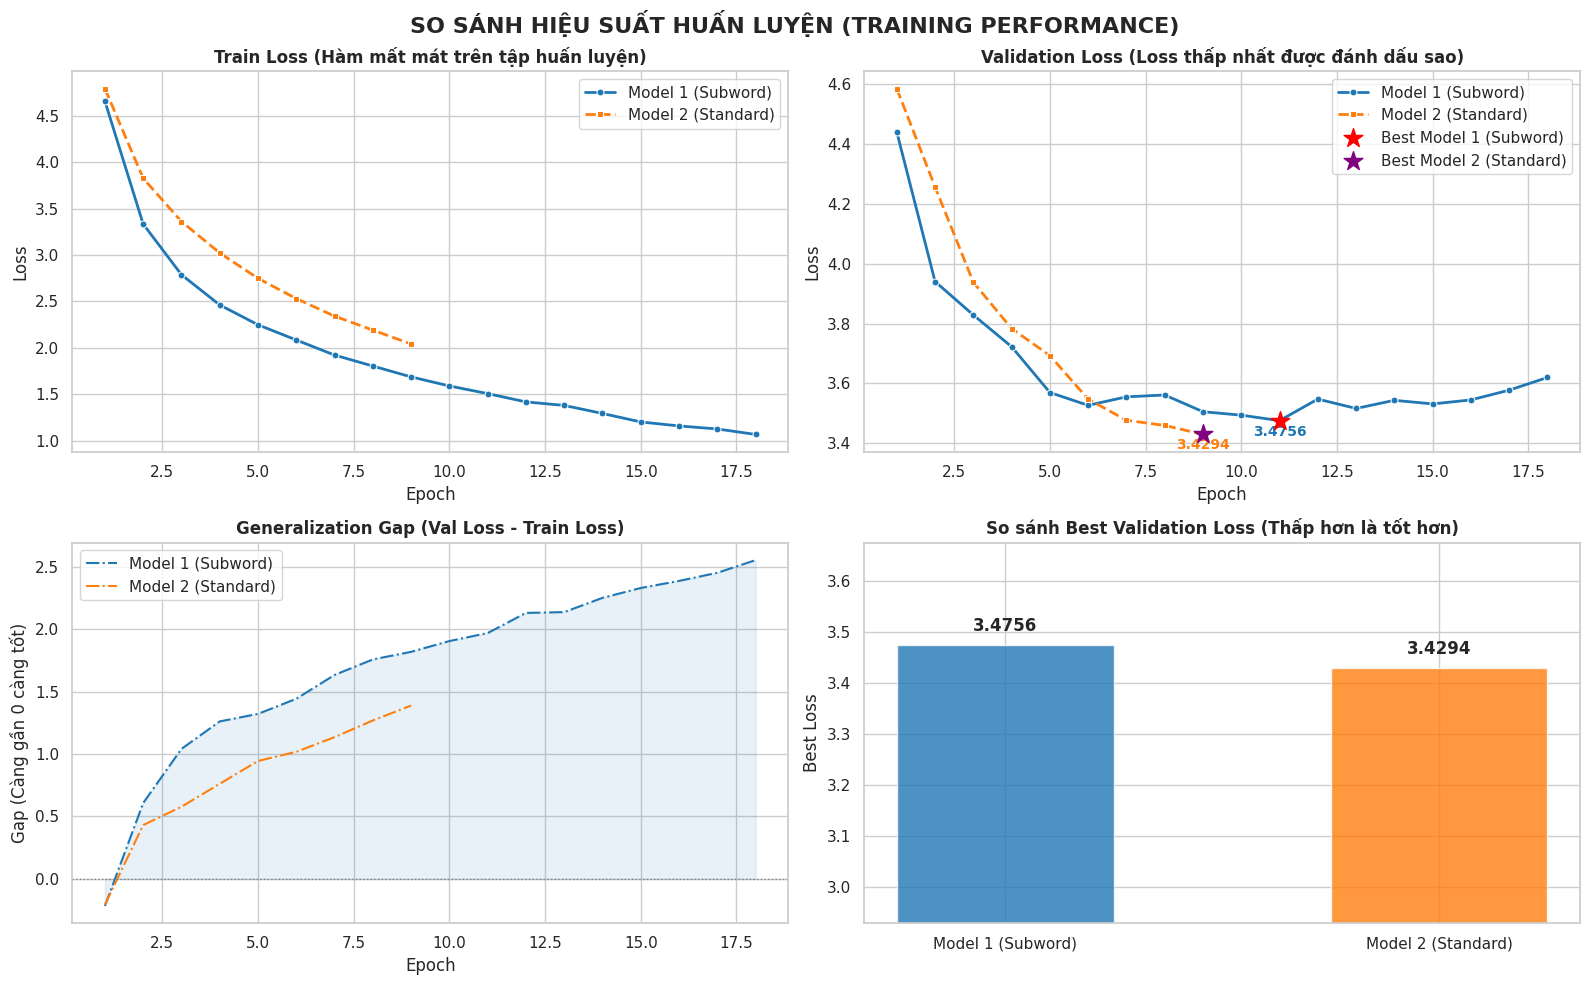

In [18]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Cấu hình style cho đẹp (Seaborn style)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

# ==========================
# 1. Load checkpoints (Giữ nguyên logic của bạn)
# ==========================
path_ckpt1 = "/content/drive/MyDrive/NLP PROJECT/last_checkpoint_subword.pth"
path_ckpt2 = "/content/drive/MyDrive/NLP PROJECT/last_checkpoint.pth"

# Load CPU để tránh lỗi nếu không có GPU
ckpt1 = torch.load(path_ckpt1, map_location="cpu")
ckpt2 = torch.load(path_ckpt2, map_location="cpu")

# Extract metrics
train1 = ckpt1["train_losses"]
val1   = ckpt1["val_losses"]
best_val1 = ckpt1.get("best_valid_loss", min(val1)) # Fallback nếu key không tồn tại

train2 = ckpt2["train_losses"]
val2   = ckpt2["val_losses"]
best_val2 = ckpt2.get("best_valid_loss", min(val2))

epochs1 = list(range(1, len(train1) + 1))
epochs2 = list(range(1, len(train2) + 1))

# Tên hiển thị cho gọn
name1 = "Model 1 (Subword)"
name2 = "Model 2 (Standard)"

# ==========================
# 2. VẼ BIỂU ĐỒ (DASHBOARD)
# ==========================
# Tạo khung hình lớn chứa 4 biểu đồ con (2x2)
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('SO SÁNH HIỆU SUẤT HUẤN LUYỆN (TRAINING PERFORMANCE)', fontsize=16, fontweight='bold')

# --- BIỂU ĐỒ 1: TRAIN LOSS ---
ax = axs[0, 0]
sns.lineplot(x=epochs1, y=train1, ax=ax, label=name1, marker='o', markersize=5, color="#1f77b4", linewidth=2)
sns.lineplot(x=epochs2, y=train2, ax=ax, label=name2, marker='s', markersize=5, color="#ff7f0e", linewidth=2, linestyle="--")
ax.set_title("Train Loss (Hàm mất mát trên tập huấn luyện)", fontweight='bold')
ax.set_ylabel("Loss")
ax.set_xlabel("Epoch")
ax.legend()

# --- BIỂU ĐỒ 2: VALIDATION LOSS (Có đánh dấu Best Model) ---
ax = axs[0, 1]
sns.lineplot(x=epochs1, y=val1, ax=ax, label=name1, marker='o', markersize=5, color="#1f77b4", linewidth=2)
sns.lineplot(x=epochs2, y=val2, ax=ax, label=name2, marker='s', markersize=5, color="#ff7f0e", linewidth=2, linestyle="--")

# Đánh dấu điểm thấp nhất (Best Val Loss)
min_idx1 = np.argmin(val1)
min_idx2 = np.argmin(val2)

ax.scatter(epochs1[min_idx1], val1[min_idx1], s=200, c='red', marker='*', zorder=10, label=f"Best {name1}")
ax.scatter(epochs2[min_idx2], val2[min_idx2], s=200, c='purple', marker='*', zorder=10, label=f"Best {name2}")

# Chú thích giá trị min ngay trên biểu đồ
ax.text(epochs1[min_idx1], val1[min_idx1]-0.05, f"{val1[min_idx1]:.4f}", color="#1f77b4", fontweight='bold', ha='center')
ax.text(epochs2[min_idx2], val2[min_idx2]-0.05, f"{val2[min_idx2]:.4f}", color="#ff7f0e", fontweight='bold', ha='center')

ax.set_title("Validation Loss (Loss thấp nhất được đánh dấu sao)", fontweight='bold')
ax.set_ylabel("Loss")
ax.set_xlabel("Epoch")
ax.legend()

# --- BIỂU ĐỒ 3: GENERALIZATION GAP (Val Loss - Train Loss) ---
# Biểu đồ này giúp xem model có bị Overfitting hay không.
# Gap càng lớn -> Overfitting càng nặng. Gap âm hoặc gần 0 -> Tốt (hoặc Underfitting).
ax = axs[1, 0]

# Tính toán Gap (Cần padding nếu độ dài epoch lệch nhau, ở đây ta vẽ theo độ dài từng model)
gap1 = np.array(val1) - np.array(train1)
gap2 = np.array(val2) - np.array(train2)

sns.lineplot(x=epochs1, y=gap1, ax=ax, label=name1, color="#1f77b4", linestyle="-.")
sns.lineplot(x=epochs2, y=gap2, ax=ax, label=name2, color="#ff7f0e", linestyle="-.")

# Vẽ đường tham chiếu tại 0
ax.axhline(0, color='gray', linewidth=1, linestyle=':')
ax.fill_between(epochs1, gap1, 0, alpha=0.1, color="#1f77b4") # Tô màu vùng gap

ax.set_title("Generalization Gap (Val Loss - Train Loss)", fontweight='bold')
ax.set_ylabel("Gap (Càng gần 0 càng tốt)")
ax.set_xlabel("Epoch")
ax.legend()

# --- BIỂU ĐỒ 4: BAR CHART SO SÁNH BEST LOSS ---
ax = axs[1, 1]
names = [name1, name2]
values = [best_val1, best_val2]
colors = ["#1f77b4", "#ff7f0e"]

bars = ax.bar(names, values, color=colors, alpha=0.8, width=0.5)

# Zoom in vào phần đỉnh của cột để thấy sự khác biệt (vì giá trị 3.47 và 3.42 rất gần nhau)
# Ta set giới hạn trục Y từ (min_value - 0.2) đến (max_value + 0.2)
y_min_lim = min(values) - 0.5
y_max_lim = max(values) + 0.2
ax.set_ylim(y_min_lim, y_max_lim)

ax.set_title("So sánh Best Validation Loss (Thấp hơn là tốt hơn)", fontweight='bold')
ax.set_ylabel("Best Loss")

# Hiển thị số liệu trên cột
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
            f'{height:.4f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [23]:
import torch

ckpt1 = torch.load("/content/drive/MyDrive/NLP PROJECT/best_model_subword.pth", map_location="cpu")
ckpt2 = torch.load("/content/drive/MyDrive/NLP PROJECT/best_model.pth", map_location="cpu")

print("=== Checkpoint 1 keys ===")
print(ckpt1.keys())

print("\n=== Checkpoint 2 keys ===")
print(ckpt2.keys())


=== Checkpoint 1 keys ===
dict_keys(['model_state_dict', 'src_vocab', 'trg_vocab', 'pad_idx'])

=== Checkpoint 2 keys ===
dict_keys(['model_state_dict', 'src_vocab', 'trg_vocab', 'pad_idx'])
